# SMS_Spam_Detection

In [1]:
# step 1:import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt  
import seaborn as sns

In [2]:
# step 2:Load the dataset
df = pd.read_csv(r"C:\Users\asusvivobook\Desktop\FSDS\ML Practicals\Navie Bayes\Spam SMS\spam_sms.csv")

In [3]:
print("\nDataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)

print("\nDataset Information:")
print(df.info())


Dataset Shape:
(5572, 2)

Columns:
Index(['v1', 'v2'], dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   v1      5572 non-null   str  
 1   v2      5572 non-null   str  
dtypes: str(2)
memory usage: 541.4 KB
None


In [4]:
# rename the column names
df = df.rename(columns={
    "v1": "label",
    "v2": "message"
})

print(df.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [5]:
# check the missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
label      0
message    0
dtype: int64


In [6]:
# check the duplicate records
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Duplicate Rows:
403


In [7]:
df = df.drop_duplicates()

print("\nShape after removing duplicates:")
print(df.shape)


Shape after removing duplicates:
(5169, 2)


In [8]:
print("\nClass Distribution:")
print(df["label"].value_counts())


Class Distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


In [9]:
# separate x and y
X = df["message"]
y = df["label"]

print(X.head())
print(y.head())

0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: str
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: str


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(X)

print("Shape of X:", X.shape)

Shape of X: (5169, 8672)


In [11]:
# split the data for training and testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4135, 8672)
Testing data: (1034, 8672)


In [12]:
# train the naive bayes
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [13]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham'
 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [14]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9535783365570599


In [15]:
from sklearn.metrics import classification_report

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       903
        spam       1.00      0.63      0.78       131

    accuracy                           0.95      1034
   macro avg       0.97      0.82      0.87      1034
weighted avg       0.96      0.95      0.95      1034



In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[903   0]
 [ 48  83]]


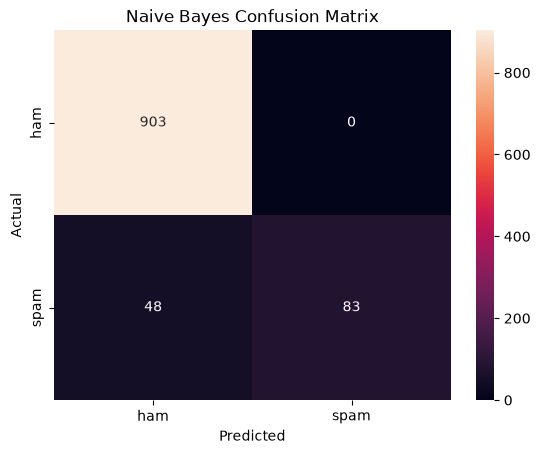

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [18]:
import joblib

joblib.dump(model, "naive_bayes_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [19]:
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Vectorizer saved successfully!")

Vectorizer saved successfully!
